In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve,roc_auc_score,auc

In [126]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [127]:
target = 'converted'
numerical = df.select_dtypes(include='number').columns.drop(target).tolist()
categorical = df.select_dtypes(exclude='number').columns.tolist()
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
print(df.isnull().sum().sum())
print(numerical)
print(categorical)



0
['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
['lead_source', 'industry', 'employment_status', 'location']


In [128]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_full_train = df_full_train[target].values
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

df_full_train = df_full_train.drop(columns=target)
df_train = df_train.drop(columns=target)
df_val = df_val.drop(columns=target)
df_test = df_test.drop(columns=target)

y_train_series = pd.Series(y_train, index=df_train.index, name=target)

print(len(df_train), len(df_val), len(df_test),len(y_train))
print(y_train.mean(), y_val.mean(), y_test.mean())
print(target in df_train.columns)

3000 1000 1000 3000
0.5763333333333334 0.586 0.568
False


In [129]:
# Question 1: ROC AUC feature importance
for feature in numerical:
    score = roc_auc_score(y_train, df_train[feature])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[feature])
    print(f"{feature}: {score:.3f}")

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


In [130]:
features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.651)

In [131]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f"{col}: {auc:.3f}")

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


In [132]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
t = 0.5
predicted_positive = (y_pred >= t)
predicted_negative = (y_pred < t)

In [133]:
tp = (predicted_positive & actual_positive).sum()
fp = (predicted_positive & actual_negative).sum()
tn = (predicted_negative & actual_negative).sum()
fn = (predicted_negative & actual_positive).sum()

In [134]:
precision = tp/(tp+fp)
recall = tp/(tp+fn)
f1 = 2 * (precision * recall) / (precision + recall)
print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')
print(f'F1: {f1:.3f}')

Precision: 0.644
Recall: 0.906
F1: 0.753


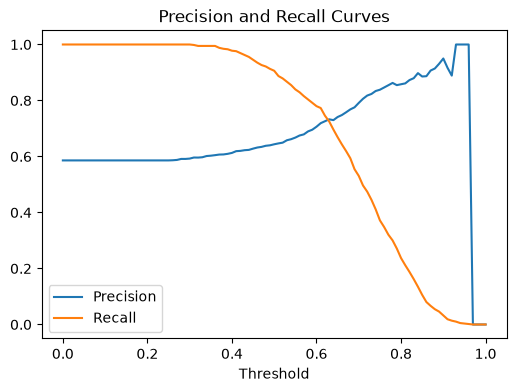

Intersection threshold: 0.97


In [135]:
# Question 3: Evaluate precision and recall across thresholds [0.0, 1.0]
thresholds = np.linspace(0, 1, 101)
pr_scores = []
y_pred = model.predict_proba(X_val)[:, 1]
for t_val in thresholds:
    p_pos = (y_pred >= t_val)
    p_neg = (y_pred < t_val)
    
    tp_val = (p_pos & (y_val == 1)).sum()
    fp_val = (p_pos & (y_val == 0)).sum()
    fn_val = (p_neg & (y_val == 1)).sum()
    
    p = tp_val / (tp_val + fp_val) if (tp_val + fp_val) > 0 else 0
    r = tp_val / (tp_val + fn_val) if (tp_val + fn_val) > 0 else 0
    
    pr_scores.append((t_val, p, r))

df_pr = pd.DataFrame(pr_scores, columns=['threshold', 'precision', 'recall'])

# Plot curve to see intersection
plt.figure(figsize=(6, 4))
plt.plot(df_pr.threshold, df_pr.precision, label='Precision')
plt.plot(df_pr.threshold, df_pr.recall, label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision and Recall Curves')
plt.show()

# Find intersection point
df_pr['diff'] = (df_pr.precision - df_pr.recall).abs()
intersection_threshold = df_pr.loc[df_pr['diff'].idxmin()]['threshold']
print(f"Intersection threshold: {intersection_threshold:.2f}")

In [136]:
# Question 4: Find threshold where F1 is maximal
df_pr['f1'] = 2 * (df_pr.precision * df_pr.recall) / (df_pr.precision + df_pr.recall)
df_pr['f1'] = df_pr['f1'].fillna(0)

best_f1_row = df_pr.loc[df_pr['f1'].idxmax()]
print(f"Max F1 threshold: {best_f1_row['threshold']:.2f} with F1: {best_f1_row['f1']:.3f}")

Max F1 threshold: 0.41 with F1: 0.758


ROC AUC

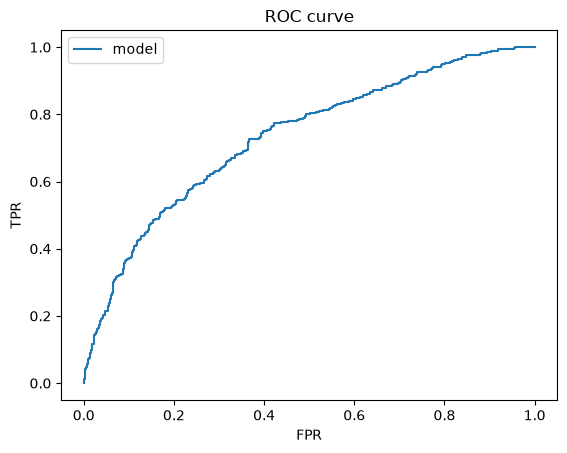

In [137]:
fpr,tpr,thresholds = roc_curve(y_val,y_pred)
plt.figsize=(6,6)
plt.plot(fpr,tpr,label="model")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC curve")
plt.legend()

In [138]:
roc_auc_score(y_val,y_pred)


0.7318222288173319

In [139]:
from sklearn.model_selection import KFold

In [140]:
def train(df,y,C=1.0):
    dicts = df[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X,y)

    return dv,model

dv,model = train(df_train,y_train,C=10)

def predict(df,dv,model):
    dicts = df[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [141]:
y_pred = predict(df_val,dv,model)

In [142]:
# Question 5: 5-Fold CV standard deviation
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]
    
    y_fold_train = y_full_train[train_idx]
    y_fold_val = y_full_train[val_idx]

    dv, model = train(df_fold_train, y_fold_train, C=1.0)
    y_fold_pred = predict(df_fold_val, dv, model)
    auc_val = roc_auc_score(y_fold_val, y_fold_pred)

    scores.append(auc_val)

print(f"5-Fold AUC scores: {scores}")
print(f"AUC mean: {np.mean(scores):.3f}")
print(f"AUC std: {np.std(scores):.3f}")

5-Fold AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
AUC mean: 0.732
AUC std: 0.007


In [143]:
# Question 6: Parameter tuning for C
c_values = [0.000001, 0.001, 1]

for C_val in c_values:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    c_scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]
        
        y_fold_train = y_full_train[train_idx]
        y_fold_val = y_full_train[val_idx]

        dv, model = train(df_fold_train, y_fold_train, C=C_val)
        y_fold_pred = predict(df_fold_val, dv, model)
        auc_val = roc_auc_score(y_fold_val, y_fold_pred)

        c_scores.append(auc_val)

    print(f"C={C_val:<8} | Mean AUC: {np.mean(c_scores):.3f} | Std: {np.std(c_scores):.3f}")

C=1e-06    | Mean AUC: 0.617 | Std: 0.019
C=0.001    | Mean AUC: 0.749 | Std: 0.010
C=1        | Mean AUC: 0.732 | Std: 0.007
